In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import plotly.express as px

In [2]:
url = "https://raw.githubusercontent.com/GeethaGunasekaran1/Dataset_rep/main/social_media_engagement_5000.csv"
df = pd.read_csv(url)

In [3]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [4]:
df["posted_at"] = pd.to_datetime(df["posted_at"], format="%d-%m-%Y")
df["posted_at"].dtype

dtype('<M8[us]')

In [6]:
likes_arr = df["likes"].dropna().to_numpy()

print(likes_arr.shape)
print(np.mean(likes_arr))
print(np.median(likes_arr))
print(np.std(likes_arr))
print(np.percentile(likes_arr, [25, 50, 75, 90]))

(4850,)
10107.043711340206
10105.5
5789.222332204696
[ 5068.5 10105.5 15115.  18076.1]


In [7]:
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [8]:
for c in ["age", "likes", "comments", "shares"]:
    df[c] = df[c].fillna(df[c].median())

for c in ["gender", "sentiment"]:
    df[c] = df[c].fillna(df[c].mode()[0])

df.isnull().sum().sum()   # should print 0

np.int64(0)

In [ ]:
df.duplicated().sum()              #  identical rows
df["post_id"].duplicated().sum()   # repeated post IDs

np.int64(9)

In [10]:
df = df.drop_duplicates(subset="post_id", keep="first").reset_index(drop=True)
df.shape

(4991, 19)

In [12]:
df[["age", "likes", "comments", "shares"]] = df[["age", "likes", "comments", "shares"]].astype(int)

In [13]:
df["gender"] = df["gender"].str.strip().str.title()
for c in ["post_type", "post_category", "device_type", "sentiment"]:
    df[c] = df[c].str.strip().str.lower()

In [14]:
(df[["likes", "comments", "shares", "watch_time_sec"]] < 0).sum()   # negatives
(df["age"] < 13).sum()                                                # impossible ages
df["interactions"] = df["likes"] + df["comments"] + df["shares"]
(df["interactions"] > df["impression_count"]).sum()                  # about 600

np.int64(599)

In [15]:
df["engagement_rate_raw"] = df["engagement_rate"]          # keep the original
df["engagement_rate"] = df["engagement_rate"].clip(upper=1.0)   # cap at 100%

In [16]:
df["hashtag_count"] = df["hashtags"].str.count("#")
df["hashtag_count"].value_counts()
df["sentiment"].unique()    # should be only positive / neutral / negative

<StringArray>
['negative', 'positive', 'neutral']
Length: 3, dtype: str

In [17]:
df.head()
df.tail()
df.shape        # (rows, columns)
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'interactions', 'engagement_rate_raw', 'hashtag_count'],
      dtype='str')

In [18]:
df.info()
df.dtypes

<class 'pandas.DataFrame'>
RangeIndex: 4991 entries, 0 to 4990
Data columns (total 22 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   user_id              4991 non-null   int64         
 1   age                  4991 non-null   int64         
 2   gender               4991 non-null   str           
 3   country              4991 non-null   str           
 4   post_id              4991 non-null   int64         
 5   post_type            4991 non-null   str           
 6   post_category        4991 non-null   str           
 7   likes                4991 non-null   int64         
 8   comments             4991 non-null   int64         
 9   shares               4991 non-null   int64         
 10  watch_time_sec       4991 non-null   int64         
 11  impression_count     4991 non-null   int64         
 12  posted_at            4991 non-null   datetime64[us]
 13  follower_count       4991 non-null   int64  

user_id                         int64
age                             int64
gender                            str
country                           str
post_id                         int64
post_type                         str
post_category                     str
likes                           int64
comments                        int64
shares                          int64
watch_time_sec                  int64
impression_count                int64
posted_at              datetime64[us]
follower_count                  int64
is_verified                      bool
device_type                       str
sentiment                         str
hashtags                          str
engagement_rate               float64
interactions                    int64
engagement_rate_raw           float64
hashtag_count                   int64
dtype: object

In [19]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,interactions,engagement_rate_raw,hashtag_count
count,4991.000000,4991.000000,4991.000000,4991.000000,4991.000000,4991.000000,4991.000000,4991.000000,4991,4991.000000,4991.000000,4991.000000,4991.000000,4991.000000
mean,54547.943699,38.439591,547854.825486,10105.831897,1501.511921,1002.897015,4015.120617,50029.706872,2022-12-28 10:38:12.286115,393904.683631,0.371150,12610.240834,0.964971,1.998998
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,193.000000,0.006363,1.000000
25%,32281.000000,26.000000,322410.000000,5224.500000,791.000000,511.000000,2023.500000,24997.000000,2022-07-03 12:00:00,195064.500000,0.145709,7800.000000,0.145709,1.000000
50%,54327.000000,38.000000,547905.000000,10105.000000,1497.000000,1012.000000,4034.000000,49954.000000,2022-12-27 00:00:00,389040.000000,0.253806,12552.000000,0.253806,2.000000
75%,77172.500000,51.000000,771256.500000,14965.000000,2234.500000,1482.500000,6020.500000,74715.500000,2023-06-27 12:00:00,589869.000000,0.504695,17481.500000,0.504695,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,1.000000,24680.000000,191.504348,3.000000
std,26094.658996,14.686923,260657.341322,5703.628075,856.683226,570.842898,2307.053146,28845.669265,NaN,230898.849565,0.304625,5782.928668,5.322732,0.813094


In [20]:
for c in ["gender", "country", "post_type", "post_category", "device_type", "sentiment", "is_verified"]:
    print(c, "-> unique:", df[c].nunique())
    print(df[c].unique())
    print(df[c].value_counts())
    print()

gender -> unique: 3
<StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str
gender
Male      1842
Other     1581
Female    1568
Name: count, dtype: int64

country -> unique: 10
<StringArray>
[   'Brazil',        'UK',    'France',    'Canada',     'Japan', 'Australia',
     'India',       'UAE',   'Germany',       'USA']
Length: 10, dtype: str
country
India        534
Canada       512
Brazil       504
UAE          502
USA          501
France       496
UK           491
Australia    490
Germany      489
Japan        472
Name: count, dtype: int64

post_type -> unique: 4
<StringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str
post_type
reel     1281
image    1244
text     1243
video    1223
Name: count, dtype: int64

post_category -> unique: 8
<StringArray>
[  'fitness',      'food',      'tech',    'travel',   'fashion', 'lifestyle',
 'education',     'music']
Length: 8, dtype: str
post_category
fitness      674
tech         665
music        634
education    630
lif

In [21]:
num_cols = ["age", "likes", "comments", "shares", "watch_time_sec",
            "impression_count", "follower_count", "engagement_rate", "hashtag_count"]
corr = df[num_cols].corr()
corr.round(2)

,age,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
age,1.00,-0.04,-0.01,0.01,0.01,0.01,-0.03,-0.03,0.01
likes,-0.04,1.00,-0.02,0.00,0.01,0.01,-0.02,0.39,-0.00
comments,-0.01,-0.02,1.00,0.01,-0.02,-0.01,-0.01,0.06,-0.01
shares,0.01,0.00,0.01,1.00,0.01,-0.00,-0.01,0.05,0.01
watch_time_sec,0.01,0.01,-0.02,0.01,1.00,-0.00,0.00,0.01,-0.02
impression_count,0.01,0.01,-0.01,-0.00,-0.00,1.00,-0.02,-0.78,-0.00
follower_count,-0.03,-0.02,-0.01,-0.01,0.00,-0.02,1.00,-0.00,0.01
engagement_rate,-0.03,0.39,0.06,0.05,0.01,-0.78,-0.00,1.00,-0.01
hashtag_count,0.01,-0.00,-0.01,0.01,-0.02,-0.00,0.01,-0.01,1.00


In [22]:
df.groupby("post_type")["likes"].mean().round(0).sort_values(ascending=False)
df.groupby("country")["impression_count"].mean().round(0).sort_values(ascending=False)

country
India        52541.0
France       51728.0
USA          51264.0
UK           51113.0
Japan        49616.0
Brazil       49193.0
UAE          48936.0
Canada       48656.0
Germany      48645.0
Australia    48423.0
Name: impression_count, dtype: float64

In [23]:
df.groupby("post_category")["comments"].mean()
df.groupby("device_type")["watch_time_sec"].mean()
df.groupby("is_verified")["engagement_rate"].mean()

is_verified
False    0.373548
True     0.348619
Name: engagement_rate, dtype: float64

In [24]:
df["engagement_score"] = (df["likes"] + 2*df["comments"] + 3*df["shares"]) / df["impression_count"] * 100

In [25]:
df["log_likes"] = np.log1p(df["likes"])
df["log_impressions"] = np.log1p(df["impression_count"])
df["log_followers"] = np.log1p(df["follower_count"])

In [26]:
df["weekday"] = df["posted_at"].dt.day_name()
df["month"] = df["posted_at"].dt.to_period("M").dt.to_timestamp()
df["age_group"] = pd.cut(df["age"], bins=[12, 17, 24, 34, 44, 54, 64],
                         labels=["13-17", "18-24", "25-34", "35-44", "45-54", "55-64"])

In [27]:
bench = df.groupby("post_type")["engagement_rate"].mean().rename("post_type_avg_rate").reset_index()
df = df.merge(bench, on="post_type", how="left")
df["vs_type_avg"] = df["engagement_rate"] - df["post_type_avg_rate"]

In [28]:
high = df[df["impression_count"] >= df["impression_count"].median()]
low  = df[df["impression_count"] <  df["impression_count"].median()]

pd.concat([
    high.assign(reach="high")[["reach", "likes", "engagement_rate"]],
    low.assign(reach="low")[["reach", "likes", "engagement_rate"]],
]).groupby("reach").mean()

,likes,engagement_rate
reach,,
high,10222.719151,0.177272
low,9988.897796,0.565107


In [29]:
agg = dict(
    posts=("post_id", "count"),
    avg_likes=("likes", "mean"),
    avg_impressions=("impression_count", "mean"),
    avg_eng_rate=("engagement_rate", "mean"),
    median_eng_rate=("engagement_rate", "median"),
    avg_score=("engagement_score", "mean"),
)

by_type    = df.groupby("post_type").agg(**agg).round(3)
by_country = df.groupby("country").agg(**agg).round(3)
by_sent    = df.groupby("sentiment").agg(**agg).round(3)

by_type.sort_values("avg_eng_rate", ascending=False)

,posts,avg_likes,avg_impressions,avg_eng_rate,median_eng_rate,avg_score
post_type,,,,,,
video,1223,10187.674,49852.859,0.376,0.247,139.883
text,1243,10099.928,49987.308,0.376,0.254,136.447
image,1244,10103.127,49778.921,0.373,0.264,114.416
reel,1281,10036.051,50483.231,0.360,0.248,102.181


In [30]:
cols = ["likes", "comments", "shares", "watch_time_sec", "engagement_rate", "follower_count"]

In [31]:
df[cols].mean()
df[cols].median()
df[cols].mode().iloc[0]     # mode() can return several rows if there are ties; iloc[0] takes the first

likes               10105.0
comments             1497.0
shares               1012.0
watch_time_sec        916.0
engagement_rate         1.0
follower_count     497502.0
Name: 0, dtype: float64

In [32]:
df[cols].std()
df[cols].var()

likes              3.253137e+07
comments           7.339062e+05
shares             3.258616e+05
watch_time_sec     5.322494e+06
engagement_rate    9.279621e-02
follower_count     5.331428e+10
dtype: float64

In [33]:
df[cols].quantile([0.25, 0.5, 0.75, 0.9, 0.99])

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
0.25,5224.5,791.0,511.0,2023.5,0.145709,195064.5
0.50,10105.0,1497.0,1012.0,4034.0,0.253806,389040.0
0.75,14965.0,2234.5,1482.5,6020.5,0.504695,589869.0
0.90,18016.0,2696.0,1796.0,7212.0,1.000000,717827.0
0.99,19857.2,2975.1,1983.0,7924.4,1.000000,792567.0


In [35]:
stats_table = pd.DataFrame({
    "mean": df[cols].mean(),
    "median": df[cols].median(),
    "mode": df[cols].mode().iloc[0],
    "std": df[cols].std(),
    "variance": df[cols].var(),
    "p25": df[cols].quantile(0.25),
    "p75": df[cols].quantile(0.75),
    "p90": df[cols].quantile(0.90),
    "skew": df[cols].skew(),
    "kurtosis": df[cols].kurt(),
})
stats_table.round(2).T

,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
mean,10105.83,1501.51,1002.90,4015.12,0.37,3.939047e+05
median,10105.00,1497.00,1012.00,4034.00,0.25,3.890400e+05
mode,10105.00,1497.00,1012.00,916.00,1.00,4.975020e+05
std,5703.63,856.68,570.84,2307.05,0.30,2.308989e+05
variance,32531373.22,733906.15,325861.61,5322494.22,0.09,5.331428e+10
p25,5224.50,791.00,511.00,2023.50,0.15,1.950645e+05
p75,14965.00,2234.50,1482.50,6020.50,0.50,5.898690e+05
p90,18016.00,2696.00,1796.00,7212.00,1.00,7.178270e+05
skew,-0.01,0.00,-0.01,-0.02,1.06,4.000000e-02
kurtosis,-1.15,-1.15,-1.15,-1.19,-0.19,-1.190000e+00


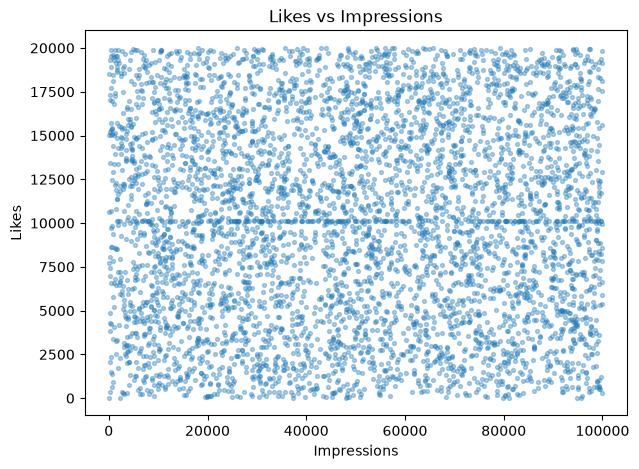

In [36]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["impression_count"], df["likes"], s=8, alpha=0.35)
ax.set_title("Likes vs Impressions")
ax.set_xlabel("Impressions")
ax.set_ylabel("Likes")
plt.show()

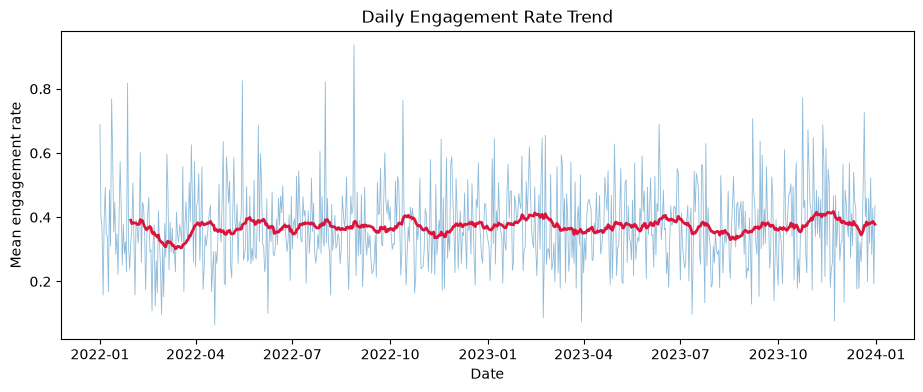

In [37]:
daily = df.groupby("posted_at")["engagement_rate"].mean()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(daily.index, daily.values, linewidth=0.6, alpha=0.5)
ax.plot(daily.rolling(30).mean(), linewidth=2, color="crimson")   # smooth 30-day line
ax.set_title("Daily Engagement Rate Trend")
ax.set_xlabel("Date")
ax.set_ylabel("Mean engagement rate")
plt.show()

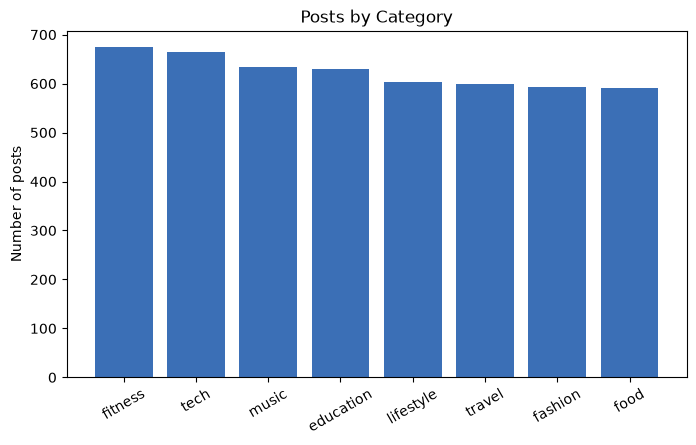

In [38]:
# Bar: posts by category
cat = df["post_category"].value_counts()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(cat.index, cat.values, color="#3b6fb6")
ax.set_title("Posts by Category")
ax.set_ylabel("Number of posts")
plt.xticks(rotation=30)
plt.show()

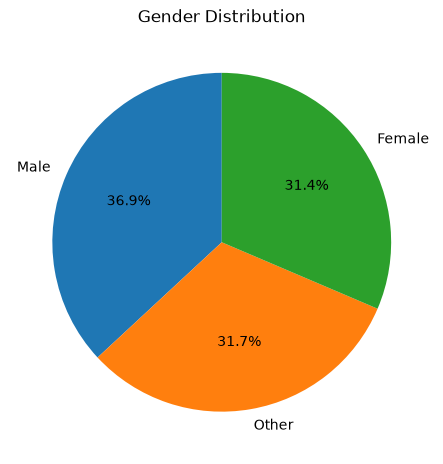

In [39]:
# Pie: gender distribution
g = df["gender"].value_counts()
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(g.values, labels=g.index, autopct="%1.1f%%", startangle=90)
ax.set_title("Gender Distribution")
plt.show()

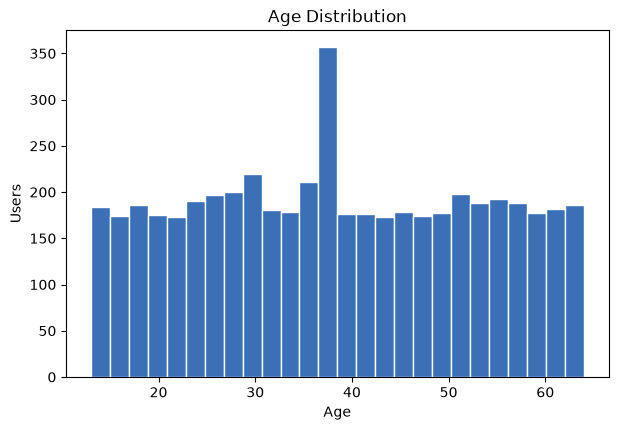

In [40]:
# Histogram: age
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(df["age"], bins=26, color="#3b6fb6", edgecolor="white")
ax.set_title("Age Distribution")
ax.set_xlabel("Age")
ax.set_ylabel("Users")
plt.show()

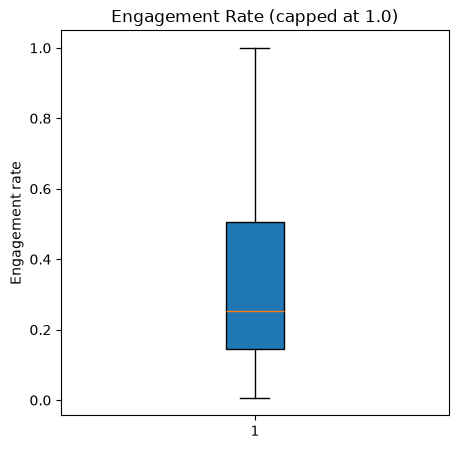

In [41]:
# Box: engagement rate
fig, ax = plt.subplots(figsize=(5, 5))
ax.boxplot(df["engagement_rate"], patch_artist=True)
ax.set_title("Engagement Rate (capped at 1.0)")
ax.set_ylabel("Engagement rate")
plt.show()

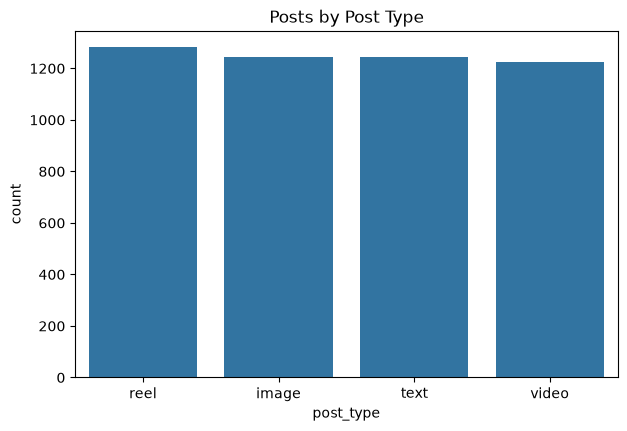

In [42]:
# Count plot: post type
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.countplot(data=df, x="post_type", order=df["post_type"].value_counts().index, ax=ax)
ax.set_title("Posts by Post Type")
plt.show()

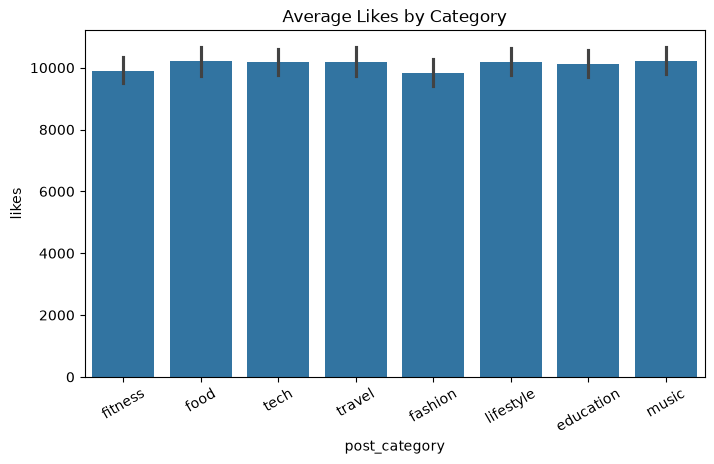

In [44]:
# Bar plot: average likes by category
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=df, x="post_category", y="likes", ax=ax)
ax.set_title("Average Likes by Category")
plt.xticks(rotation=30)
plt.show()

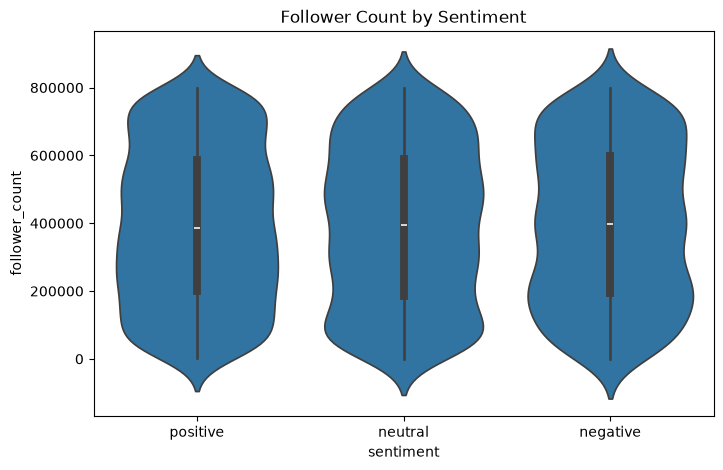

In [45]:
# Violin: followers vs sentiment
fig, ax = plt.subplots(figsize=(8, 5))
sns.violinplot(data=df, x="sentiment", y="follower_count", order=["positive", "neutral", "negative"], ax=ax)
ax.set_title("Follower Count by Sentiment")
plt.show()

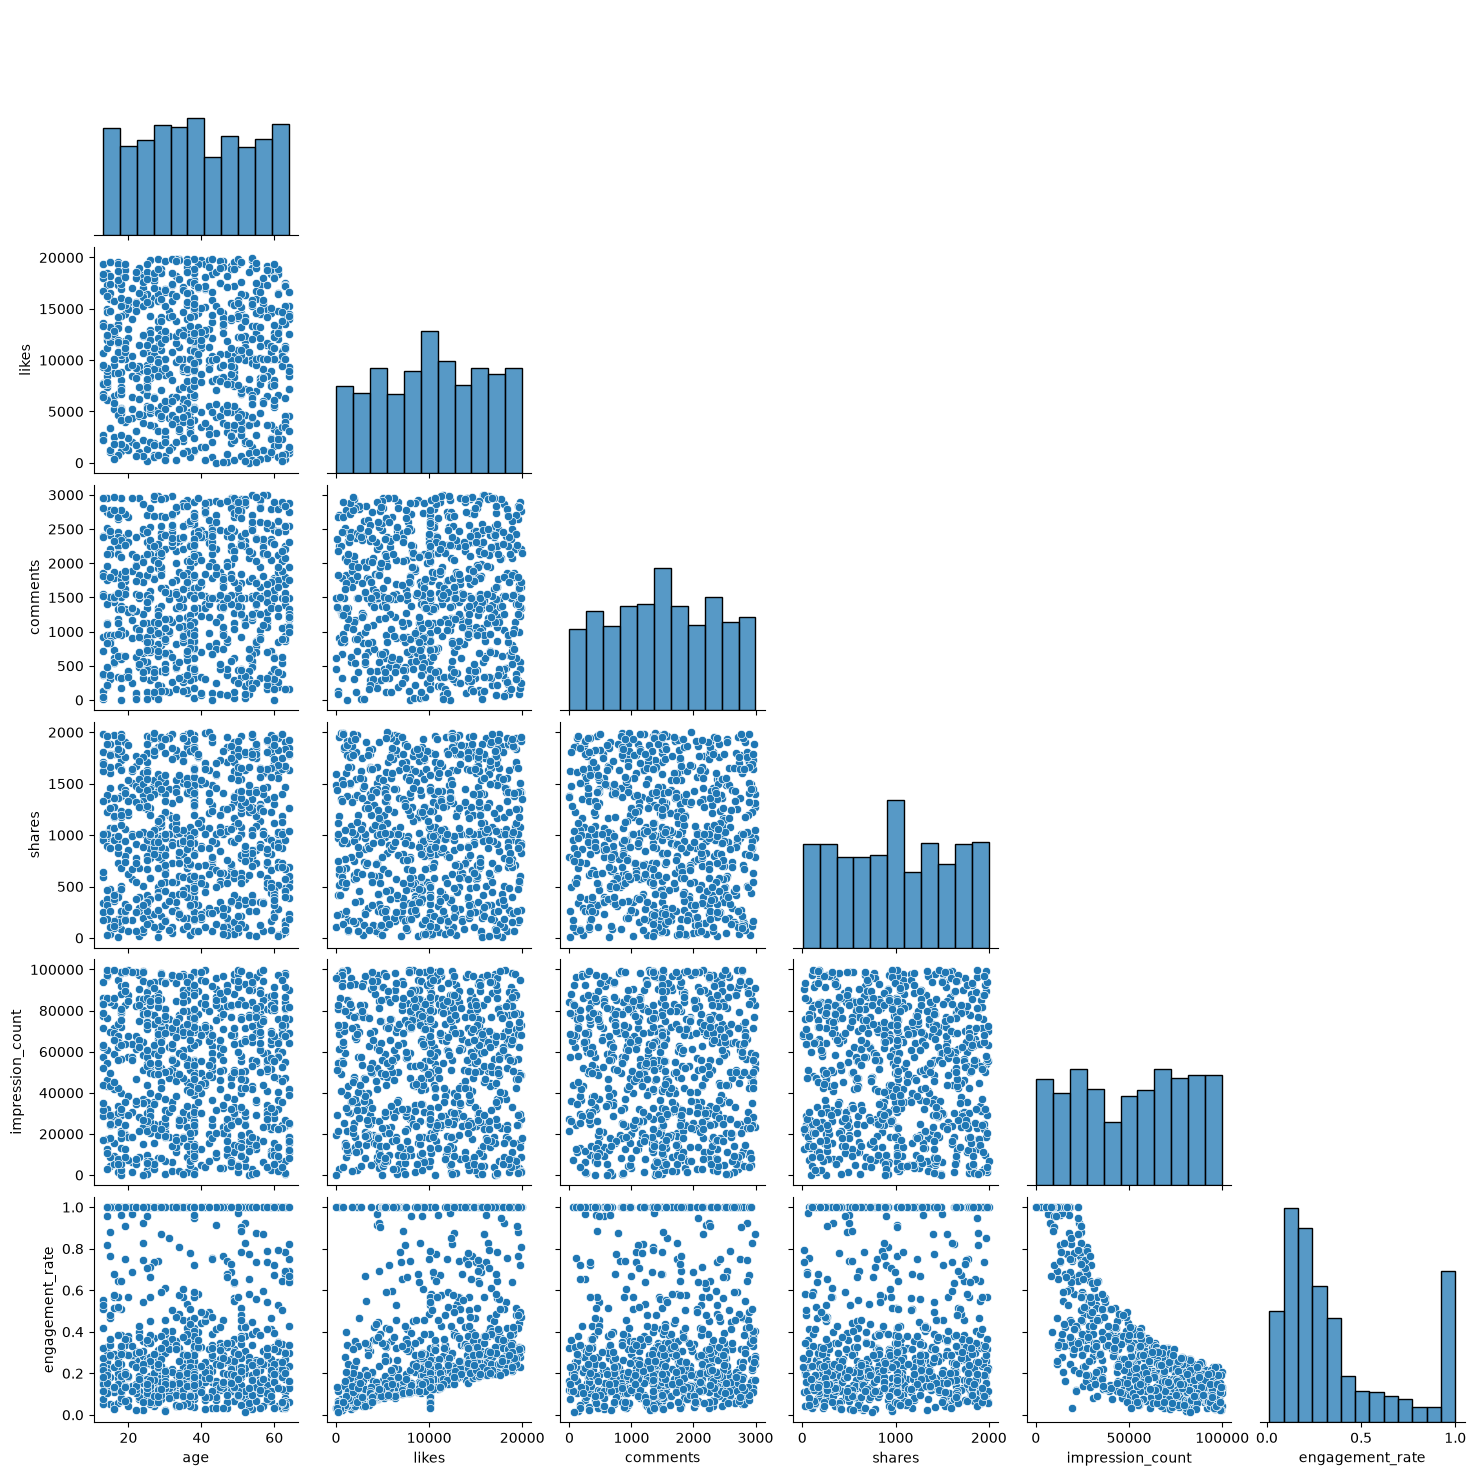

In [46]:
# Pair plot: numeric features (sample, because the full data is slow)
cols = ["age", "likes", "comments", "shares", "impression_count", "engagement_rate"]
sns.pairplot(df.sample(800, random_state=1)[cols], corner=True)
plt.show()

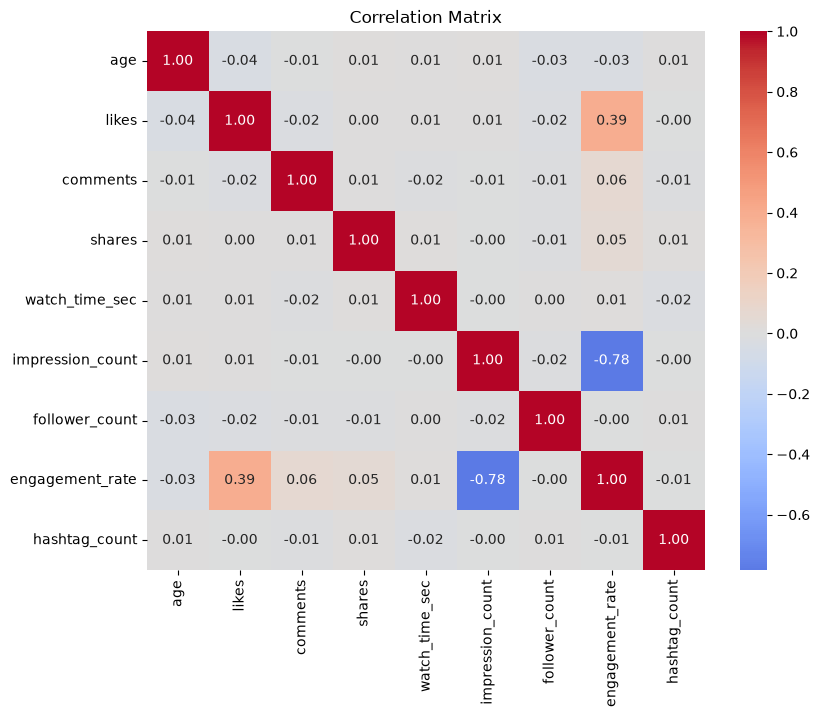

In [47]:
# Heatmap: correlation matrix
num_cols = ["age", "likes", "comments", "shares", "watch_time_sec",
            "impression_count", "follower_count", "engagement_rate", "hashtag_count"]
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Matrix")
plt.show()

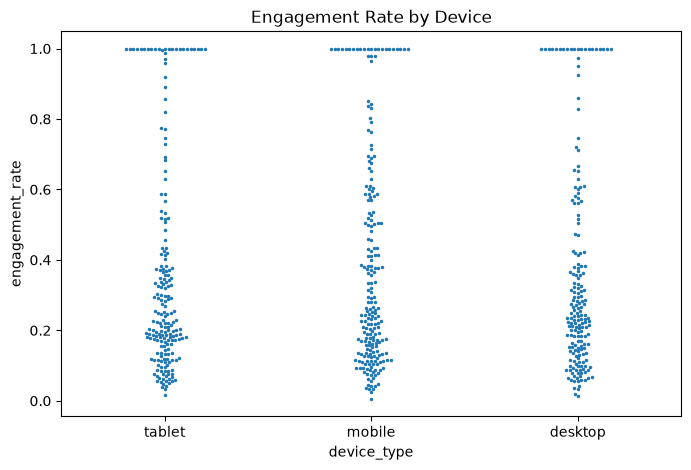

In [48]:
# Swarm: engagement vs device (sample)
fig, ax = plt.subplots(figsize=(8, 5))
sns.swarmplot(data=df.sample(600, random_state=2), x="device_type", y="engagement_rate", size=2.5, ax=ax)
ax.set_title("Engagement Rate by Device")
plt.show()

In [51]:
!pip install plotly


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [52]:
m = df.groupby(["month", "post_type"])["engagement_rate"].mean().reset_index()
px.line(m, x="month", y="engagement_rate", color="post_type",
        title="Monthly Engagement Rate by Post Type")

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'hovertemplate': 'post_type=image<br>month=%{x}<br>engagement_rate=%{y}<extra></extra>',
              'legendgroup': 'image',
              'line': {'color': '#636efa', 'dash': 'solid'},
              'marker': {'symbol': 'circle'},
              'mode': 'lines',
              'name': 'image',
              'orientation': 'v',
              'showlegend': True,
              'type': 'scatter',
              'x': array(['2022-01-01T00:00:00.000000', '2022-02-01T00:00:00.000000',
                          '2022-03-01T00:00:00.000000', '2022-04-01T00:00:00.000000',
                          '2022-05-01T00:00:00.000000', '2022-06-01T00:00:00.000000',
                          '2022-07-01T00:00:00.000000', '2022-08-01T00:00:00.000000',
                          '2022-09-01T00:00:00.000000', '2022-10-01T00:00:00.000000',
                          '2022-11-01T00:00:00.000000', '2022-12-01T00:00:00.000000',
                          '2023-01-01T00:00:00.000000', '2023-02-01T00:00:00.000000',
                          '2023-03-01T00:00:00.000000', '2023-04-01T00:00:00.000000',
                          '2023-05-01T00:00:00.000000', '2023-06-01T00:00:00.000000',
                          '2023-07-01T00:00:00.000000', '2023-08-01T00:00:00.000000',
                          '2023-09-01T00:00:00.000000', '2023-10-01T00:00:00.000000',
                          '2023-11-01T00:00:00.000000', '2023-12-01T00:00:00.000000'],
                         dtype='datetime64[us]'),
              'xaxis': 'x',
              'y': {'bdata': ('GSmrUkbw1z8sd17gdyrVP01qtjrPkd' ... '3LVBUe2D9XG7Hhw0DaP2D+f6aiQNw/'),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'hovertemplate': 'post_type=reel<br>month=%{x}<br>engagement_rate=%{y}<extra></extra>',
              'legendgroup': 'reel',
              'line': {'color': '#EF553B', 'dash': 'solid'},
              'marker': {'symbol': 'circle'},
              'mode': 'lines',
              'name': 'reel',
              'orientation': 'v',
              'showlegend': True,
              'type': 'scatter',
              'x': array(['2022-01-01T00:00:00.000000', '2022-02-01T00:00:00.000000',
                          '2022-03-01T00:00:00.000000', '2022-04-01T00:00:00.000000',
                          '2022-05-01T00:00:00.000000', '2022-06-01T00:00:00.000000',
                          '2022-07-01T00:00:00.000000', '2022-08-01T00:00:00.000000',
                          '2022-09-01T00:00:00.000000', '2022-10-01T00:00:00.000000',
                          '2022-11-01T00:00:00.000000', '2022-12-01T00:00:00.000000',
                          '2023-01-01T00:00:00.000000', '2023-02-01T00:00:00.000000',
                          '2023-03-01T00:00:00.000000', '2023-04-01T00:00:00.000000',
                          '2023-05-01T00:00:00.000000', '2023-06-01T00:00:00.000000',
                          '2023-07-01T00:00:00.000000', '2023-08-01T00:00:00.000000',
                          '2023-09-01T00:00:00.000000', '2023-10-01T00:00:00.000000',
                          '2023-11-01T00:00:00.000000', '2023-12-01T00:00:00.000000'],
                         dtype='datetime64[us]'),
              'xaxis': 'x',
              'y': {'bdata': ('9UnI6eYo1z8qorR8CDbWP1qWNtDpF9' ... 'v8fqYV2D9bVBFGiUbXPxgclBz46NE/'),
                    'dtype': 'f8'},
              'yaxis': 'y'},
             {'hovertemplate': 'post_type=text<br>month=%{x}<br>engagement_rate=%{y}<extra></extra>',
              'legendgroup': 'text',
              'line': {'color': '#00cc96', 'dash': 'solid'},
              'marker': {'symbol': 'circle'},
              'mode': 'lines',
              'name': 'text',
              'orientation': 'v',
              'showlegend': True,
              'type': 'scatter',
              'x': array(['2022-01-01T00:00:00.000000', '2022-02-01T00:00:00.000000',
                          '2022-03-01T00:00:00.000000', '2022-04-01T00:00:00.000000',
                          '2022-05-0

In [53]:
by_country = df.groupby("country")["engagement_rate"].mean().reset_index()
px.bar(by_country, x="country", y="engagement_rate", title="Average Engagement Rate by Country")

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'hovertemplate': 'country=%{x}<br>engagement_rate=%{y}<extra></extra>',
              'legendgroup': '',
              'marker': {'color': '#636efa', 'pattern': {'shape': ''}},
              'name': '',
              'orientation': 'v',
              'showlegend': False,
              'textposition': 'auto',
              'type': 'bar',
              'x': array(['Australia', 'Brazil', 'Canada', 'France', 'Germany', 'India', 'Japan',
                          'UAE', 'UK', 'USA'], dtype=object),
              'xaxis': 'x',
              'y': {'bdata': ('8qduC2s12T/V2+wycgrYP22eobpEMd' ... 'lyKYbYPykaN3BbqNY/gK4bTv/41j8='),
                    'dtype': 'f8'},
              'yaxis': 'y'}],
    'layout': {'barmode': 'relative',
               'legend': {'tracegroupgap': 0},
               'template': '...',
               'title': {'text': 'Average Engagement Rate by Country'},
               'xaxis': {'anchor': 'y', 'domain': [0.0, 1.0], 'title': {'text': 'country'}},
               'yaxis': {'anchor': 'x', 'domain': [0.0, 1.0], 'title': {'text': 'engagement_rate'}}}
})

In [54]:
px.scatter(df.sample(1000, random_state=3), x="impression_count", y="likes",
           size="follower_count", color="post_type", title="Likes vs Impressions")

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'hovertemplate': ('post_type=reel<br>impression_c' ... '=%{marker.size}<extra></extra>'),
              'legendgroup': 'reel',
              'marker': {'color': '#636efa',
                         'size': {'bdata': ('UkQLAERXAwBpIgUA6XUCAHa4AACkzw' ... 'oIAMr5CwD07QYAbnQIAM1hAAALGwMA'),
                                  'dtype': 'i4'},
                         'sizemode': 'area',
                         'sizeref': 1998.7325,
                         'symbol': 'circle'},
              'mode': 'markers',
              'name': 'reel',
              'orientation': 'v',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('NYgAAK8HAQDquAAAyyMBAHdDAAAVOw' ... 'QAAPD6AABjcAAAE+kAABs7AQDTsQAA'),
                    'dtype': 'i4'},
              'xaxis': 'x',
              'y': {'bdata': ('izGUN5FHyUDzTDcKtESjH5czDjp9IX' ... 'qSDtAqbRV5J2Y9NShdNystQk3YIT4M'),
                    'dtype': 'i2'},
              'yaxis': 'y'},
             {'hovertemplate': ('post_type=text<br>impression_c' ... '=%{marker.size}<extra></extra>'),
              'legendgroup': 'text',
              'marker': {'color': '#EF553B',
                         'size': {'bdata': ('pR0BAKabAADZKggAugILANL9AwCuiQ' ... 'sFAITZBAC76QgA6JcBACoOCgA65QkA'),
                                  'dtype': 'i4'},
                         'sizemode': 'area',
                         'sizeref': 1998.7325,
                         'symbol': 'circle'},
              'mode': 'markers',
              'name': 'text',
              'orientation': 'v',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('Sd0AABo8AADoGgAA3RoAAMDbAADPXQ' ... 'cBAFOBAQBALgAA/BoBAEYcAQB+SgEA'),
                    'dtype': 'i4'},
              'xaxis': 'x',
              'y': {'bdata': ('Q0IoF1oaXQkTSL4EaQB5Jz9MQgOTCb' ... 'aLBy4UqwhREWpBYhrQMkpMMCAcJVwW'),
                    'dtype': 'i2'},
              'yaxis': 'y'},
             {'hovertemplate': ('post_type=image<br>impression_' ... '=%{marker.size}<extra></extra>'),
              'legendgroup': 'image',
              'marker': {'color': '#00cc96',
                         'size': {'bdata': ('1BAHAAaECQCgigUAPloAAJwTCAAhrA' ... 'ELAJtSBwD7rQEADMoBAGfKCwCxoQkA'),
                                  'dtype': 'i4'},
                         'sizemode': 'area',
                         'sizeref': 1998.7325,
                         'symbol': 'circle'},
              'mode': 'markers',
              'name': 'image',
              'orientation': 'v',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('CKUAAPyYAACXMgEABQkAAJRrAACxbw' ... 'gAAGQfAAD/YQEASQ4BAAmkAAAWMAEA'),
                    'dtype': 'i4'},
              'xaxis': 'x',
              'y': {'bdata': ('q0uIBMATUS7MO8lAewSfJ+Y3Pz6FKn' ... '2CGa0ylCBsFdoNpA/CBxMmMzECB1ZL'),
                    'dtype': 'i2'},
              'yaxis': 'y'},
             {'hovertemplate': ('post_type=video<br>impression_' ... '=%{marker.size}<extra></extra>'),
              'legendgroup': 'video',
              'marker': {'color': '#ab63fa',
                         'size': {'bdata': ('x9wGADdMCQDAewYA1A8FAM3pBwBTXA' ... 'D0BQEAGcoGANsvBQCdngkAtBEEAA=='),
                                  'dtype': 'i4'},
                         'sizemode': 'area',
                         'sizeref': 1998.7325,
                         'symbol': 'circle'},
              'mode': 'markers',
              'name': 'video',
              'orientation': 'v',
              'showlegend': True,
              'type': 'scatter',
              'x': {'bdata': ('8QkAACBsAQDeIAEAfSQBAAwiAAD4Mg' ... 'DTnAAAm7kAAAU1AADGEAAAfdAAAA=='),
                    'dtype': 'i4'},
              'xaxis': 'x',
              'y': {'bdata': ('z0e6PoA3qRKHOREndT7yJTQNgBbBFq' ... 'APokNaF5wP5kifTahNkj1gIR8F3Qo='),
                    'dtype': 'i2'},
              'yaxis': 'y'}],
    'layout': {'legend': {'itemsizing'

In [ ]:
# Content performance
df.groupby("post_type")["engagement_rate"].mean().sort_values(ascending=False)
df.groupby("post_category")["engagement_rate"].mean().sort_values(ascending=False)
df.groupby("country")["engagement_rate"].mean().sort_values(ascending=False)

country
Australia    0.393885
Japan        0.384591
UAE          0.383189
Germany      0.379303
Canada       0.378007
Brazil       0.375638
France       0.367336
USA          0.358948
UK           0.354026
India        0.339553
Name: engagement_rate, dtype: float64

In [56]:
# User trends
df.groupby("age_group")["engagement_rate"].mean()
df["age"].corr(df["engagement_rate"])
df.groupby("is_verified")[["engagement_rate", "likes"]].mean()

,engagement_rate,likes
is_verified,,
False,0.373548,10139.552649
True,0.348619,9788.927083


In [57]:
# Behaviour (the data has dates only, so use weekday and month instead of time of day)
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df.groupby("weekday")["impression_count"].mean().reindex(order)
df.groupby("device_type")["watch_time_sec"].mean()

device_type
desktop    3975.813406
mobile     4087.612136
tablet     3980.800484
Name: watch_time_sec, dtype: float64

In [59]:
# Sentiment
df.groupby("sentiment")[["likes", "comments", "shares", "engagement_rate"]].mean()
df["sentiment"].value_counts(normalize=True)

sentiment
positive    0.502505
neutral     0.305550
negative    0.191946
Name: proportion, dtype: float64